# 03 · Análisis exploratorio orientado por preguntas (Fase 5)

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from IPython.display import display, Markdown
pd.set_option("display.max_columns", 30)
from src.config import *
df = pd.read_parquet(PROCESSED / "emovi_movilidad.parquet")
q1 = df[df.sigue_q1.notna()]
from src.visualization import plots as V
import matplotlib.pyplot as plt

## P1. ¿Qué tanto se hereda la posición?

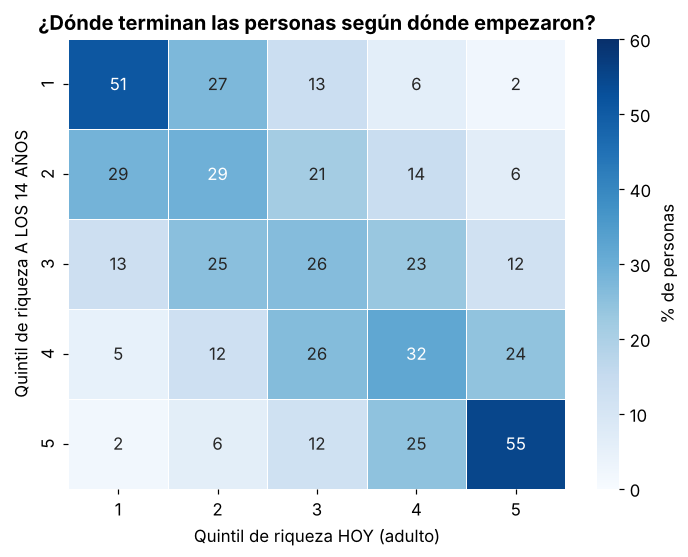

In [2]:
fig, tm = V.matriz_transicion(df); tm.to_csv(TABLES / "matriz_transicion.csv"); plt.show()

**Lectura:** la diagonal concentra a la mayoría. Los extremos son los más "pegajosos": de quienes nacen en Q1, la mitad sigue ahí; de quienes nacen en Q5, más de la mitad sigue ahí. Solo 2 de cada 100 personas pasan de Q1 a Q5.

## P2 y P4. ¿Para quién es más pegajosa la pobreza?

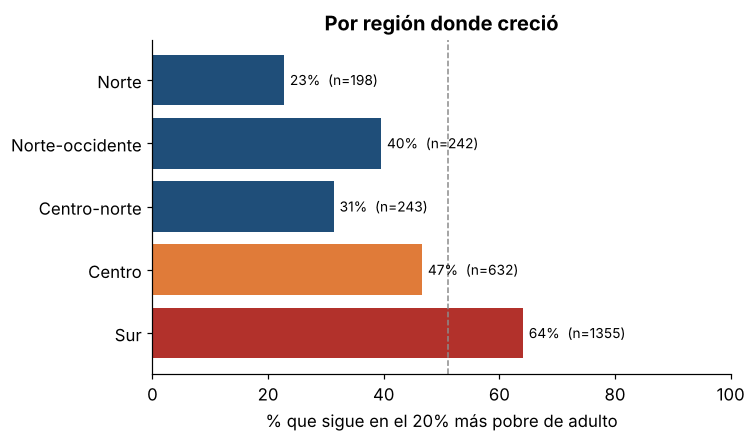

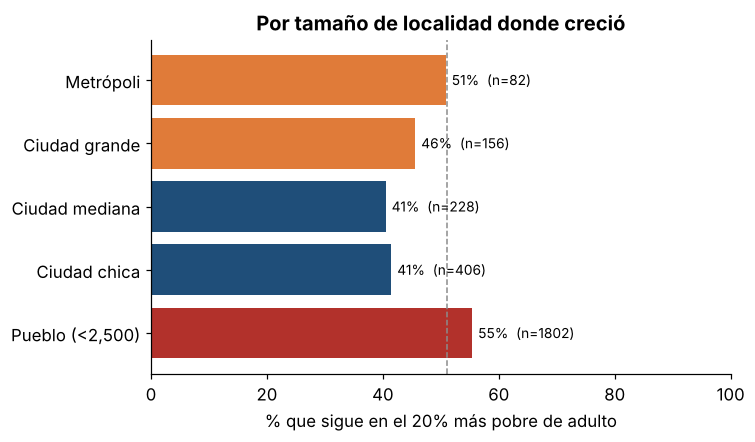

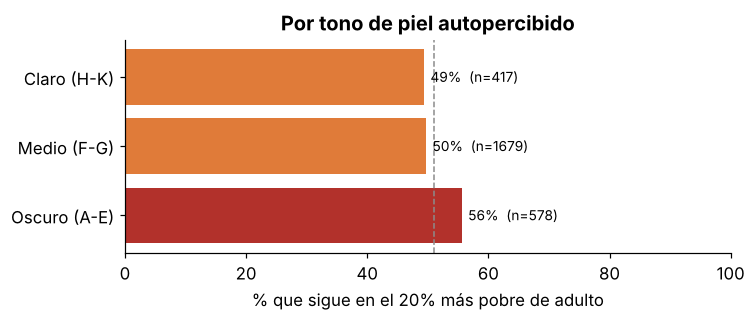

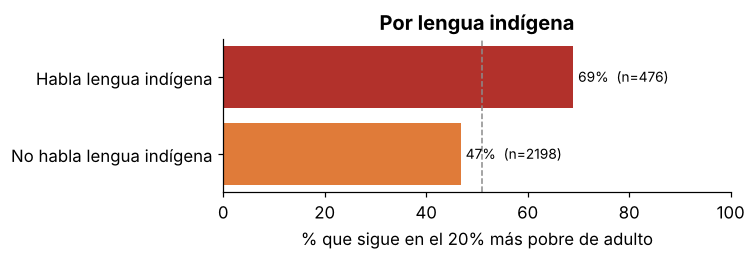

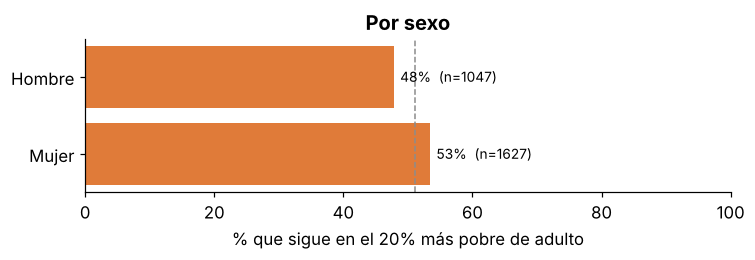

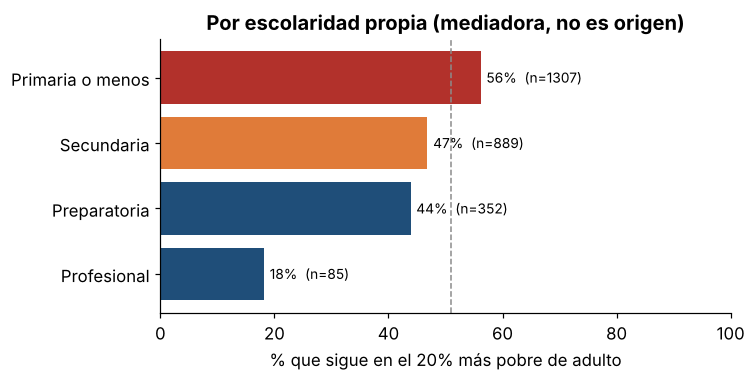

In [3]:
res = {}
fig, res["region"] = V.barras_grupo(df, "region_14", "Por región donde creció", "02_por_region", ["Norte","Norte-occidente","Centro-norte","Centro","Sur"]); plt.show()
fig, res["localidad"] = V.barras_grupo(df, "localidad_14", "Por tamaño de localidad donde creció", "03_por_localidad", ["Metrópoli","Ciudad grande","Ciudad mediana","Ciudad chica","Pueblo (<2,500)"]); plt.show()
d = df.assign(lengua=df.lengua_indigena.map({0:"No habla lengua indígena",1:"Habla lengua indígena"}), sexo=df.mujer.map({0:"Hombre",1:"Mujer"}))
fig, res["tono"] = V.barras_grupo(d, "tono_piel", "Por tono de piel autopercibido", "04a_por_tono", ["Claro (H-K)","Medio (F-G)","Oscuro (A-E)"]); plt.show()
fig, res["lengua"] = V.barras_grupo(d, "lengua", "Por lengua indígena", "04b_por_lengua"); plt.show()
fig, res["sexo"] = V.barras_grupo(d, "sexo", "Por sexo", "04c_por_sexo"); plt.show()
fig, res["educ"] = V.barras_grupo(d, "educ", "Por escolaridad propia (mediadora, no es origen)", "04d_por_educ_propia", ["Primaria o menos","Secundaria","Preparatoria","Profesional"]); plt.show()
pd.concat(res, names=["dimension"]).to_csv(TABLES / "sigue_q1_por_grupo.csv")

## P5. ¿El contexto del estado importa?

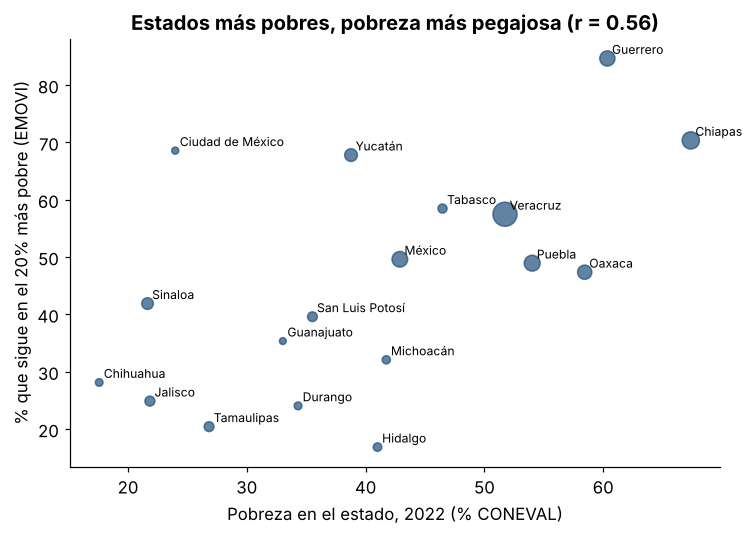

Correlación con informalidad (ENOE): 0.46


In [4]:
ctx = pd.read_csv(PROCESSED / "contexto_estatal_2022.csv", index_col=0)
fig, est, r = V.contexto_estatal(df, ctx); est.to_csv(TABLES / "contexto_vs_persistencia.csv"); plt.show()
print("Correlación con informalidad (ENOE):", round(np.corrcoef(est.informalidad_pct, est.pct)[0,1], 2))

**Cuidado:** la pobreza de 2022 describe al estado **hoy**, no cuando las personas tenían 14 años. Se usa como señal de que la persistencia y la pobreza estructural van juntas, no como causa. Solo se grafican los estados con al menos 40 casos.